# Plan EDA VGEC 2026
Notebook này thực hiện 12 stages EDA cho dữ liệu VGEC 2026 theo yêu cầu đề xuất.


In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata
import Levenshtein
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')


## Stage 0 — Raw-data preservation & schema validation
Giữ nguyên VGEC 2026_v1.json và v2.json, tuyệt đối chưa normalize/chỉnh dữ liệu. Parse từng record thành schema chuẩn id, input, error_type, references[].


In [2]:
def validate_and_parse(file_path):
    issues = []
    try:
        with open(file_path, 'r', encoding='utf-8') as f:
            raw_data = json.load(f)
    except Exception as e:
        issues.append(f"JSON Load Error: {e}")
        return pd.DataFrame(), issues

    parsed = []
    for idx, item in enumerate(raw_data):
        input_text = item.get('Input', '')
        if input_text != unicodedata.normalize('NFC', input_text):
            issues.append(f"Row {idx}: Input is not NFC normalized.")
            
        output = item.get('Output', {})
        fixed = output.get('Fixed Sentence')
        
        if isinstance(fixed, str):
            refs = [fixed]
        elif isinstance(fixed, list):
            refs = fixed
        else:
            refs = []
            
        for r in refs:
            if r != unicodedata.normalize('NFC', r):
                issues.append(f"Row {idx}: Reference is not NFC normalized.")
        
        parsed.append({
            'id': item.get('ID'),
            'input': input_text,
            'error_type': output.get('Error_Type_Id'),
            'references': refs
        })
        
    df = pd.DataFrame(parsed)
    
    # Missing/null checks
    if df['id'].isnull().any():
        issues.append("Missing IDs found")
    if not df['id'].is_unique:
        issues.append("Duplicate IDs found")
    if df['input'].isnull().any() or (df['input'] == '').any():
        issues.append("Empty or null Input found")
        
    return df, issues

df_v1, issues_v1 = validate_and_parse('VGEC 2026_v1.json')
df_v2, issues_v2 = validate_and_parse('VGEC 2026_v2.json')

print("V1 Issues:", len(issues_v1))
print("V2 Issues:", len(issues_v2))

# Save data integrity report
with open('data_integrity_report.txt', 'w', encoding='utf-8') as f:
    f.write("V1 Issues:\n" + "\n".join(issues_v1) + "\n\n")
    f.write("V2 Issues:\n" + "\n".join(issues_v2) + "\n")
    
print(f"Loaded V1: {len(df_v1)} records")
print(f"Loaded V2: {len(df_v2)} records")
df_v2.head()


V1 Issues: 0
V2 Issues: 0
Loaded V1: 401 records
Loaded V2: 457 records


,id,input,error_type,references
0,1,Với đôi tay khéo léo và óc thẩm mĩ tinh tế cho...,1,"[Với đôi tay khéo léo và óc thẩm mĩ tinh tế, n..."
1,2,Với nền nghệ thuật phong phú của dân tộc Khơ-m...,1,[Nền nghệ thuật phong phú của dân tộc Khơ-me đ...
2,3,"Qua cuộc sống tối tăm, u uất của chị Dậu đã tố...",1,"[Cuộc sống tối tăm, u uất của chị Dậu đã tố cá..."
3,4,Khái quát lịch sử di dân và sự hình thành nhữn...,1,[Lịch sử di dân và sự hình thành những vùng si...
4,5,"Thế rồi những khó khăn liên miên, nhất là tron...",1,"[Thế rồi trước những khó khăn liên miên, nhất ..."


## Stage 1 — V1 ↔ V2 differential audit
Join trực tiếp theo ID và kiểm tra input_changed, label_changed, reference_changed, new_sample, removed_sample. Phân tích riêng 56 sample mới.


In [3]:
merged = pd.merge(df_v1, df_v2, on='id', how='outer', suffixes=('_v1', '_v2'), indicator=True)

new_samples = merged[merged['_merge'] == 'right_only']
removed_samples = merged[merged['_merge'] == 'left_only']
common_samples = merged[merged['_merge'] == 'both'].copy()

print(f"New samples in V2: {len(new_samples)}")
print(f"Removed samples in V2: {len(removed_samples)}")

common_samples['input_changed'] = common_samples['input_v1'] != common_samples['input_v2']
common_samples['error_type_changed'] = common_samples['error_type_v1'] != common_samples['error_type_v2']
common_samples['reference_changed'] = common_samples.apply(lambda row: set(row['references_v1']) != set(row['references_v2']), axis=1)

print("Changed Inputs:", common_samples['input_changed'].sum())
print("Changed Error Types:", common_samples['error_type_changed'].sum())
print("Changed References:", common_samples['reference_changed'].sum())

print("\n--- Distribution comparison ---")
print("V1 Distribution (IDs 1-401):")
print(df_v1['error_type'].value_counts().sort_index())
print("\nV2 Distribution (Total):")
print(df_v2['error_type'].value_counts().sort_index())

print("\nV2 Distribution (New Samples IDs >= 402):")
print(df_v2[df_v2['id'] >= 402]['error_type'].value_counts().sort_index())

# Export v1_v2_diff.csv
diff_df = common_samples[common_samples['input_changed'] | common_samples['error_type_changed'] | common_samples['reference_changed']]
diff_df.to_csv('v1_v2_diff.csv', index=False)



New samples in V2: 56
Removed samples in V2: 0
Changed Inputs: 0
Changed Error Types: 0
Changed References: 0

--- Distribution comparison ---
V1 Distribution (IDs 1-401):
error_type
0    200
1     98
2     34
3     33
4     36
Name: count, dtype: int64

V2 Distribution (Total):
error_type
0    200
1    154
2     34
3     33
4     36
Name: count, dtype: int64

V2 Distribution (New Samples IDs >= 402):
error_type
1    56
Name: count, dtype: int64


## Stage 2 — Label/Error-type analysis
Thống kê số lượng và tỷ lệ Error_Type_Id = 0..4, sau đó lấy representative examples mỗi class để phân tích empirically các transformation.


In [4]:
error_counts = df_v2['error_type'].value_counts(normalize=True) * 100
print("Error Type Proportions (%):\n", error_counts.sort_index())

print("\nRepresentative examples per error type:")
for err_type in sorted(df_v2['error_type'].dropna().unique()):
    print(f"\n{'='*40}\nError Type: {err_type}\n{'='*40}")
    samples = df_v2[df_v2['error_type'] == err_type].head(3)
    for _, row in samples.iterrows():
        print(f"ID : {row['id']}")
        print(f"IN : {row['input']}")
        print(f"OUT: {row['references']}")
        print("-" * 20)



Error Type Proportions (%):
 error_type
0    43.763676
1    33.698031
2     7.439825
3     7.221007
4     7.877462
Name: proportion, dtype: float64

Representative examples per error type:

Error Type: 0
ID : 202
IN : Bản đồ là hình ảnh thu nhỏ một phần hay toàn bộ bề mặt Trái Đất lên mặt phẳng, trên cơ sở toán học nhất định.
OUT: []
--------------------
ID : 203
IN : Phép chiếu hình nón là cách thể hiện mạng lưới kinh, vĩ tuyến của Địa cầu lên mặt chiếu là mặt hình nón.
OUT: []
--------------------
ID : 204
IN : Phương pháp kí hiệu thường dùng để biểu hiện các đối tượng phân bố theo những điểm cụ thể.
OUT: []
--------------------

Error Type: 1
ID : 1
IN : Với đôi tay khéo léo và óc thẩm mĩ tinh tế cho nên người thợ trẻ đã tạo ra được những sản phẩm mành trúc có giá trị.
OUT: ['Với đôi tay khéo léo và óc thẩm mĩ tinh tế, người thợ trẻ đã tạo ra được những sản phẩm mành trúc có giá trị.']
--------------------
ID : 2
IN : Với nền nghệ thuật phong phú của dân tộc Khơ-me đã góp phần không

## Stage 3 — Input/target linguistic statistics
Đo character length, token length, punctuation density, digit/date, ngoặc/quote...


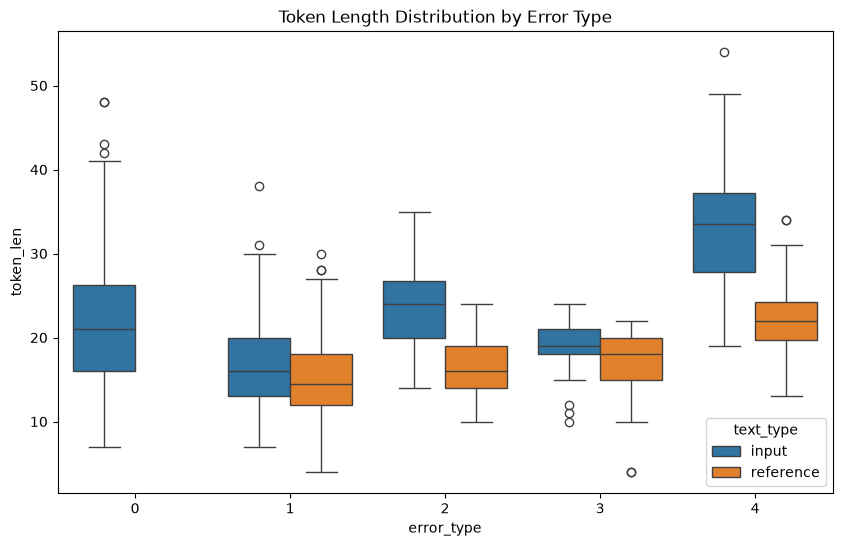

In [5]:
def compute_linguistic_stats(text):
    return {
        'char_len': len(text),
        'token_len': len(text.split()),
        'punct_count': sum(1 for c in text if unicodedata.category(c).startswith('P')),
        'digit_count': sum(1 for c in text if c.isdigit()),
        'quotes_count': text.count('"') + text.count("'"),
        'ellipsis_count': text.count('...')
    }

stats_list = []
for _, row in df_v2.iterrows():
    in_stats = compute_linguistic_stats(row['input'])
    in_stats['id'] = row['id']
    in_stats['error_type'] = row['error_type']
    in_stats['text_type'] = 'input'
    stats_list.append(in_stats)
    
    for ref in row['references']:
        ref_stats = compute_linguistic_stats(ref)
        ref_stats['id'] = row['id']
        ref_stats['error_type'] = row['error_type']
        ref_stats['text_type'] = 'reference'
        stats_list.append(ref_stats)

df_stats = pd.DataFrame(stats_list)

plt.figure(figsize=(10, 6))
sns.boxplot(x='error_type', y='token_len', hue='text_type', data=df_stats)
plt.title('Token Length Distribution by Error Type')
plt.show()

df_stats.to_csv('sample_statistics.csv', index=False)



## Stage 4 — Edit-complexity EDA
Tính Levenshtein/Edit Distance, normalized edit distance. Chia examples thành minimal edit, moderate correction, heavy rewrite.


Edit Category Distribution:
edit_category
heavy_rewrite          284
moderate_correction    107
minimal_edit            66
Name: count, dtype: int64


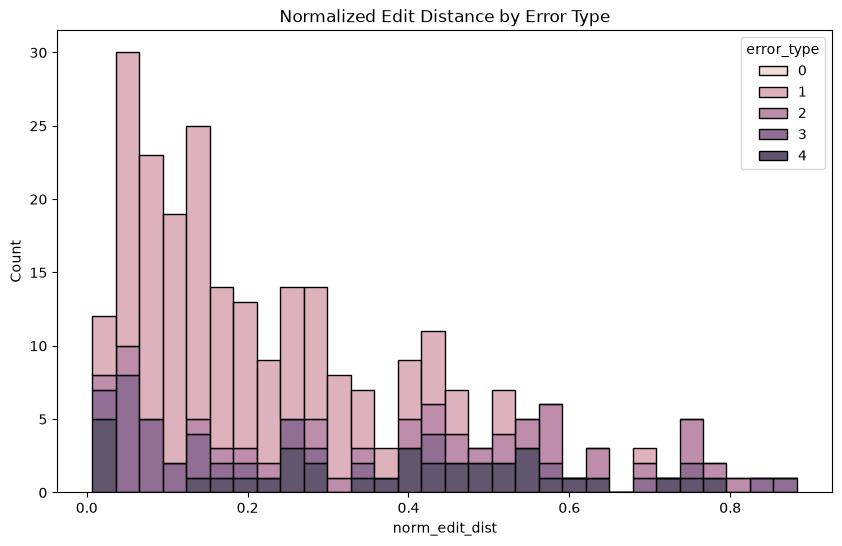

In [6]:
def calculate_edit_complexity(input_text, references):
    if not references: return None
    dists = []
    for ref in references:
        dist = Levenshtein.distance(input_text, ref)
        norm_dist = dist / max(len(input_text), len(ref), 1)
        dists.append(norm_dist)
    return min(dists)

df_v2['norm_edit_dist'] = df_v2.apply(lambda row: calculate_edit_complexity(row['input'], row['references']), axis=1)

def categorize_edit(dist):
    if dist == 0: return 'zero_edit'
    if dist < 0.1: return 'minimal_edit'
    if dist < 0.3: return 'moderate_correction'
    return 'heavy_rewrite'

df_v2['edit_category'] = df_v2['norm_edit_dist'].apply(categorize_edit)

print("Edit Category Distribution:")
print(df_v2['edit_category'].value_counts())

plt.figure(figsize=(10, 6))
sns.histplot(data=df_v2, x='norm_edit_dist', hue='error_type', multiple='stack', bins=30)
plt.title('Normalized Edit Distance by Error Type')
plt.show()



## Stage 5 — Multi-reference analysis
Đo pairwise similarity giữa các gold answers cho 56 sample có nhiều reference.


Samples with multiple references: 56


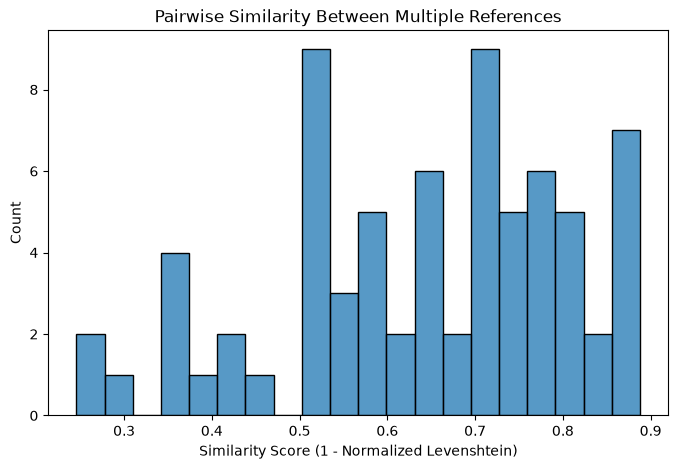

In [7]:
multi_ref_df = df_v2[df_v2['references'].apply(len) > 1]
print(f"Samples with multiple references: {len(multi_ref_df)}")

pairwise_sims = []
for _, row in multi_ref_df.iterrows():
    refs = row['references']
    for r1, r2 in combinations(refs, 2):
        sim = 1 - (Levenshtein.distance(r1, r2) / max(len(r1), len(r2), 1))
        pairwise_sims.append(sim)

if pairwise_sims:
    plt.figure(figsize=(8, 5))
    sns.histplot(pairwise_sims, bins=20)
    plt.title('Pairwise Similarity Between Multiple References')
    plt.xlabel('Similarity Score (1 - Normalized Levenshtein)')
    plt.show()
    
multi_ref_df[['id', 'input', 'references']].to_csv('reference_statistics.csv', index=False)



## Stage 6 — Annotation quality audit
Viết rule scanner để flag các target bất thường: có chứa instruction, target giống hệt Input nhưng báo lỗi, ...


In [8]:
anomalies = []
for _, row in df_v2.iterrows():
    for i, ref in enumerate(row['references']):
        reasons = []
        if "(Câu này đúng" in ref or "(Sửa" in ref:
            reasons.append("Contains instruction/explanation")
        if "hoặc:" in ref.lower() or "/" in ref:
            reasons.append("Contains alternatives (hoặc: / slash)")
        if len(ref.split()) < 3 and len(row['input'].split()) > 5:
            reasons.append("Target suspiciously short")
        if ref == row['input'] and row['error_type'] != 0:
            reasons.append(f"Target matches Input but Error_Type is {row['error_type']}")
            
        if reasons:
            anomalies.append({
                'id': row['id'],
                'input': row['input'],
                'reference_index': i,
                'reference': ref,
                'reasons': ", ".join(reasons)
            })

df_anomalies = pd.DataFrame(anomalies)
print(f"Found {len(df_anomalies)} anomalous references.")
if not df_anomalies.empty:
    df_anomalies.to_csv('annotation_anomalies.csv', index=False)
    display(df_anomalies.head())



Found 9 anomalous references.


,id,input,reference_index,reference,reasons
0,103,Đây là mô hình mới khá lý tưởng đối với vùng đ...,0,(Sửa lại nòng cốt câu để làm rõ quan hệ sở chỉ...,Contains instruction/explanation
1,104,Hội đồng Bảo an LHQ ngày 5-11 nhất trí với bản...,0,"(Câu này đúng ngữ pháp, dùng để minh họa cấu t...",Contains instruction/explanation
2,105,Việc đóng góp quân sự này mỗi ngày sẽ làm tiêu...,0,"(Câu này đúng ngữ pháp, minh họa cấu trúc bổ n...",Contains instruction/explanation
3,108,"Bộ Thủy sản cần phối hợp với các ngành, địa ph...",0,(Sửa để các hành động phối hợp và sửa đổi có t...,Contains instruction/explanation
4,116,Nhân kỷ niệm 100 năm ngày mất nhà soạn nhạc vĩ...,0,"(Câu này đúng, minh họa cho cấu trúc khởi ngữ ...",Contains instruction/explanation


## Stage 7 — Duplicate & leakage analysis
Phát hiện exact duplicate và nhóm vào cùng group_id để tránh data leakage khi split.


In [9]:
# Exact duplicate input
dup_inputs = df_v2[df_v2.duplicated(subset=['input'], keep=False)]
print(f"Exact input duplicates: {len(dup_inputs)}")

# Group duplicates
df_v2['group_id'] = df_v2.groupby('input').ngroup()

if not dup_inputs.empty:
    dup_inputs.sort_values('input').to_csv('duplicate_groups.csv', index=False)



Exact input duplicates: 13


## Stage 8 — Clean vs correct-sentence analysis
So sánh distribution độ dài giữa Error_Type=0 và các loại lỗi khác.


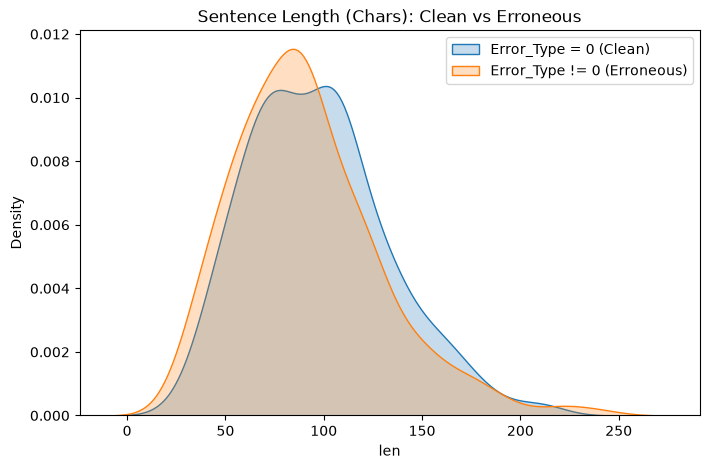

In [10]:
clean_df = df_v2[df_v2['error_type'] == 0].copy()
err_df = df_v2[df_v2['error_type'] != 0].copy()

clean_df['len'] = clean_df['input'].apply(len)
err_df['len'] = err_df['input'].apply(len)

plt.figure(figsize=(8, 5))
sns.kdeplot(clean_df['len'], label='Error_Type = 0 (Clean)', fill=True)
sns.kdeplot(err_df['len'], label='Error_Type != 0 (Erroneous)', fill=True)
plt.title('Sentence Length (Chars): Clean vs Erroneous')
plt.legend()
plt.show()



## Stage 9 — Source/domain/style analysis
Phân tích topic và lexical style: phát hiện các style viết cũ (Mĩ, kỉ, dấu cách trước hai chấm).


In [11]:
keywords = {
    'old_spelling': ['Mĩ', 'kỉ', 'lí', 'kĩ'],
    'spacing_issues': [' :', ' ...', '( ', ' )']
}

def spot_keywords(text):
    found = []
    for category, words in keywords.items():
        for w in words:
            if w in text:
                found.append(w)
    return found

df_v2['style_markers'] = df_v2['input'].apply(spot_keywords)
styles = df_v2[df_v2['style_markers'].apply(len) > 0]
print(f"Found {len(styles)} samples with specific style/formatting markers.")



Found 48 samples with specific style/formatting markers.


## Stage 10 — Build an EDA-safe split proposal
Tạo dev split stratified theo Error_Type_Id và grouped duplicate.


In [12]:
from sklearn.model_selection import train_test_split

unique_groups = df_v2.drop_duplicates(subset=['group_id'])

# Stratified split by error type (simplified)
train_groups, dev_groups = train_test_split(
    unique_groups['group_id'], 
    test_size=0.2, 
    stratify=unique_groups['error_type'], 
    random_state=42
)

df_v2['split'] = df_v2['group_id'].apply(lambda g: 'train' if g in train_groups.values else 'dev')

print("Proposed Split Sizes (Rows):")
print(df_v2['split'].value_counts())

print("\nDev Set Error Distribution (%):")
print(df_v2[df_v2['split'] == 'dev']['error_type'].value_counts(normalize=True) * 100)



Proposed Split Sizes (Rows):
split
train    364
dev       93
Name: count, dtype: int64

Dev Set Error Distribution (%):
error_type
0    43.010753
1    34.408602
2     7.526882
3     7.526882
4     7.526882
Name: proportion, dtype: float64


## Stage 11 — Final EDA artifacts
Xuất các file báo cáo tổng hợp để review.


In [13]:
summary = {
    'total_samples': len(df_v2),
    'new_in_v2': len(new_samples),
    'error_distribution': df_v2['error_type'].value_counts().to_dict(),
    'anomalies_count': len(df_anomalies),
    'duplicate_groups': int(df_v2['group_id'].nunique()),
    'multi_reference_count': len(multi_ref_df)
}

with open('eda_summary.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, indent=4)

markdown_content = f"""# VGEC 2026 EDA Report

## 1. Data Overview
- Total samples in V2: {summary['total_samples']}
- New samples in V2 (vs V1): {summary['new_in_v2']}

## 2. Key Findings
- Anomalous annotations found: {summary['anomalies_count']}
- Multi-reference samples: {summary['multi_reference_count']}
- Unique duplicate groups: {summary['duplicate_groups']}

## 3. Recommendations
- Review `annotation_anomalies.csv` to fix manual errors in gold data before training.
- Use `group_id` for splitting to avoid leakage.
- Pay attention to `edit_category` for curriculum learning or balancing.
"""

with open('EDA_REPORT.md', 'w', encoding='utf-8') as f:
    f.write(markdown_content)

print("All artifacts generated successfully: eda_summary.json, EDA_REPORT.md, and CSV files.")



All artifacts generated successfully: eda_summary.json, EDA_REPORT.md, and CSV files.
